# Assumption Checks and Statistical Tests

Formal tests that back up (or challenge) the claims made in notebooks 01-07. Each section names the notebook it supports.

| Section | Supports | Tests |
|---|---|---|
| 1. Predictor-outcome associations | 01 EDA | Chi-square + Cramér's V, Kruskal-Wallis + ε² |
| 2. Multicollinearity | 01 EDA, 02/03 | (Generalized) VIF, exact-redundancy check |
| 3. Logistic regression assumptions | 02, 03 | Likelihood-ratio test on nested models, Box-Tidwell, Cook's distance |
| 4. Linear regression assumptions | 06 | Breusch-Pagan, White, Jarque-Bera, Ramsey RESET, HC3 robust SEs |
| 5. Is the model gap real? | 07 | McNemar, corrected resampled t-test |

**A note on sample size:** with n = 4,424, almost any test rejects H₀ for even a trivially small effect. Every test below is paired with an effect size (Cramér's V, ε², VIF, pseudo-R²), and the effect size is what we interpret.

In [ ]:
import sys
from pathlib import Path

# Make `src` importable whether Jupyter starts in notebooks/ or the project root
cwd = Path.cwd()
project_root = cwd if (cwd / "requirements.txt").exists() else cwd.parent
sys.path.append(str(project_root))

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.diagnostic import het_breuschpagan, het_white, linear_reset
from statsmodels.stats.stattools import jarque_bera

from src.evaluate import evaluate_feature_set
from src.models import get_logistic_regression, get_random_forest
from src.preprocessing import (
    BINARY_COLS,
    CATEGORICAL_COLS,
    NUMERIC_COLS,
    TARGET_COL,
    build_model_pipeline,
    get_feature_availability_sets,
    load_data,
)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
FIG_DIR = project_root / "reports" / "figures"
ALPHA = 0.05

df = load_data()
feature_sets = get_feature_availability_sets(df)
y = df[TARGET_COL]
print(df.shape)

(4424, 37)


### Helper: collapsing rare category levels

Several categorical predictors have dozens of levels with only a handful of students each (e.g. Father's occupation has 46 levels, 34 of them with fewer than 30 students). That breaks two things:

- **Chi-square tests** assume expected cell counts ≥ 5. With rare levels, most cells fall below that, and the p-value isn't reliable.
- **Unpenalized logistic regression** (needed for p-values and likelihood-ratio tests) can't estimate a coefficient for a level where one outcome never occurs (*separation*). The coefficient runs off to ±∞ and the fit doesn't converge.

So for **inference only**, levels with fewer than 50 students, or with fewer than 5 students in any outcome class, are pooled into an `"Other"` level. The predictive models in 02-05 are unchanged.

In [2]:
def collapse_rare_levels(s, target=y, min_count=50, min_cell=5):
    """Pool levels that are too small overall or in any outcome class into 'Other'."""
    ct = pd.crosstab(s, target)
    rare = ct.index[(ct.sum(axis=1) < min_count) | (ct.min(axis=1) < min_cell)]
    return s.where(~s.isin(rare), "Other").astype(str)

df_collapsed = df.copy()
for c in CATEGORICAL_COLS:
    df_collapsed[c] = collapse_rare_levels(df[c])

pd.DataFrame({
    "Original levels": [df[c].nunique() for c in CATEGORICAL_COLS],
    "After collapsing": [df_collapsed[c].nunique() for c in CATEGORICAL_COLS],
}, index=CATEGORICAL_COLS)

,Original levels,After collapsing
Marital status,6,4
Application mode,18,10
Course,17,17
Previous qualification,17,4
Nacionality,21,2
Mother's qualification,29,7
Father's qualification,34,7
Mother's occupation,32,9
Father's occupation,46,11


## 1. Predictor-outcome associations (supports notebook 01)

### 1.1 Categorical and binary predictors: chi-square test of independence + Cramér's V

H₀: the predictor and the final outcome are independent. Cramér's V measures strength (0 = none, ~0.1 small, ~0.3 medium, ~0.5 large). The last two columns show the share of cells with expected count < 5, before and after collapsing rare levels. The usual rule of thumb is that it should stay under 20%.

In [3]:
def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct)[0]
    n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

def pct_small_expected(ct):
    return (stats.contingency.expected_freq(ct) < 5).mean()

rows = []
for c in CATEGORICAL_COLS + BINARY_COLS:
    ct_raw = pd.crosstab(df[c], y)
    ct = pd.crosstab(df_collapsed[c], y)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    rows.append({
        "Predictor": c, "Chi2": chi2, "df": dof, "p-value": p,
        "Cramér's V": cramers_v(ct),
        "% exp<5 (raw)": pct_small_expected(ct_raw),
        "% exp<5 (collapsed)": pct_small_expected(ct),
    })

chi_df = pd.DataFrame(rows).sort_values("Cramér's V", ascending=False).reset_index(drop=True)
chi_df["Significant"] = chi_df["p-value"] < ALPHA
display(chi_df.round(4))

,Predictor,Chi2,df,p-value,Cramér's V,% exp<5 (raw),% exp<5 (collapsed),Significant
0,Tuition fees up to date,823.5527,2,0.0000,0.4315,0.0000,0.0000,True
1,Scholarship holder,409.9431,2,0.0000,0.3044,0.0000,0.0000,True
2,Course,558.2845,32,0.0000,0.2512,0.0392,0.0392,True
3,Debtor,259.3332,2,0.0000,0.2421,0.0000,0.0000,True
4,Gender,233.2664,2,0.0000,0.2296,0.0000,0.0000,True
5,Application mode,441.5182,18,0.0000,0.2234,0.2963,0.0000,True
6,Previous qualification,165.5081,6,0.0000,0.1368,0.4902,0.0000,True
7,Father's qualification,147.2836,12,0.0000,0.1290,0.6961,0.0000,True
8,Mother's qualification,134.2647,12,0.0000,0.1232,0.6667,0.0000,True
9,Displaced,57.7542,2,0.0000,0.1143,0.0000,0.0000,True


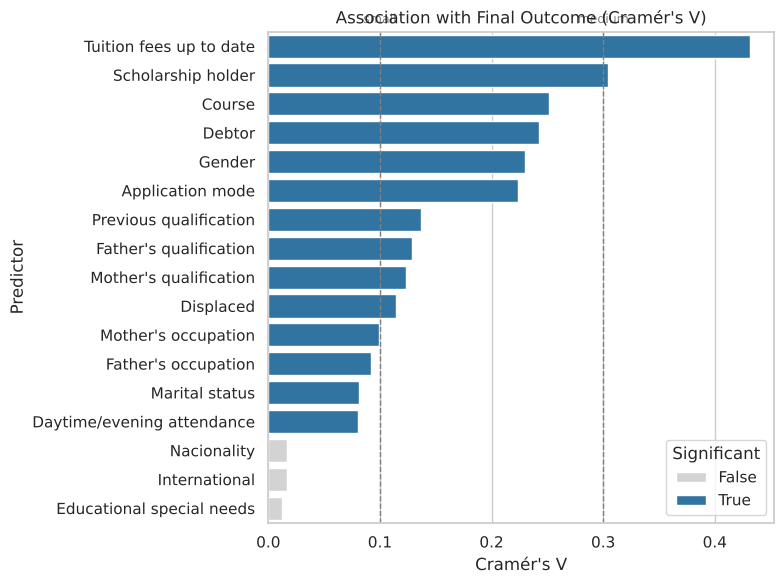

In [4]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(data=chi_df, y="Predictor", x="Cramér's V", hue="Significant",
            dodge=False, palette={True: "tab:blue", False: "lightgray"}, ax=ax)
for x, lab in [(0.1, "small"), (0.3, "medium")]:
    ax.axvline(x, ls="--", c="gray", lw=1)
    ax.text(x, -0.8, lab, ha="center", fontsize=9, color="gray")
ax.set_title("Association with Final Outcome (Cramér's V)")
plt.tight_layout()
plt.show()

**Reading this:** *Tuition fees up to date* (V ≈ 0.43) and *Scholarship holder* (V ≈ 0.30) have the strongest associations of any Day-1 variable. *Course*, *Debtor*, *Gender*, and *Application mode* are in the 0.2-0.25 range. The parental variables are all significant but weak (V ≈ 0.09-0.13). *International*, *Educational special needs*, and *Nacionality* are not significantly associated with the outcome.

Without collapsing, 60-85% of the cells for the parental and nationality variables have expected counts below 5, so their raw chi-square p-values wouldn't have been trustworthy. After collapsing, every test meets the expected-count rule.

### 1.2 Numeric predictors: Kruskal-Wallis test + ε²

H₀: the distribution of the predictor is the same across Dropout / Enrolled / Graduate. Kruskal-Wallis is used instead of one-way ANOVA because most of these variables are skewed or have a spike at zero (see the 01 histograms), which violates ANOVA's normality assumption. ε² = (H − k + 1)/(n − k) is the effect size (~0.01 small, ~0.06 medium, ~0.14 large).

In [5]:
classes = ["Dropout", "Enrolled", "Graduate"]
n, k = len(df), len(classes)
rows = []
for c in NUMERIC_COLS:
    H, p = stats.kruskal(*[df.loc[y == cls, c] for cls in classes])
    rows.append({"Predictor": c, "H": H, "p-value": p, "ε²": (H - k + 1) / (n - k),
                 **{f"Median ({cls})": df.loc[y == cls, c].median() for cls in classes}})

kw_df = pd.DataFrame(rows).sort_values("ε²", ascending=False).reset_index(drop=True)
kw_df["Significant"] = kw_df["p-value"] < ALPHA
display(kw_df.round(4))

,Predictor,H,p-value,ε²,Median (Dropout),Median (Enrolled),Median (Graduate),Significant
0,Curricular units 2nd sem (approved),1892.2765,0.0000,0.4276,0.0000,4.00,6.00,True
1,Curricular units 1st sem (approved),1561.7395,0.0000,0.3528,2.0000,5.00,6.00,True
2,Curricular units 2nd sem (grade),1390.7313,0.0000,0.3141,0.0000,12.00,13.00,True
3,Curricular units 1st sem (grade),1094.1865,0.0000,0.2470,10.9286,12.00,13.00,True
4,Age at enrollment,375.1069,0.0000,0.0844,23.0000,20.00,19.00,True
5,Curricular units 2nd sem (enrolled),270.7315,0.0000,0.0608,6.0000,6.00,6.00,True
6,Curricular units 1st sem (enrolled),246.6171,0.0000,0.0553,6.0000,6.00,6.00,True
7,Curricular units 2nd sem (evaluations),182.9464,0.0000,0.0409,7.0000,9.00,8.00,True
8,Curricular units 1st sem (evaluations),130.6588,0.0000,0.0291,8.0000,9.00,8.00,True
9,Admission grade,73.2347,0.0000,0.0161,123.6000,124.10,127.40,True


**Reading this:** the semester performance variables dominate. *2nd sem approved* (ε² ≈ 0.43) and *1st sem approved* (ε² ≈ 0.35) are large effects, followed by the semester grades. *Age at enrollment* is the strongest Day-1 numeric variable (ε² ≈ 0.08, medium). *Admission grade* and *Previous qualification grade* are significant but small (ε² ≈ 0.015). The macroeconomic variables are close to zero, and *Inflation rate* and *1st sem credited* are not significant. This lines up with the feature-availability result in notebook 03: almost all of the signal arrives with semester data.

### 1.3 How correlated are the parental variables, really?

Notebook 01 showed a Pearson correlation heatmap of the parental codes. Pearson is technically wrong for nominal codes (the numeric order of occupation codes has no meaning), so this redoes it with Cramér's V, the correct association measure between two categorical variables.

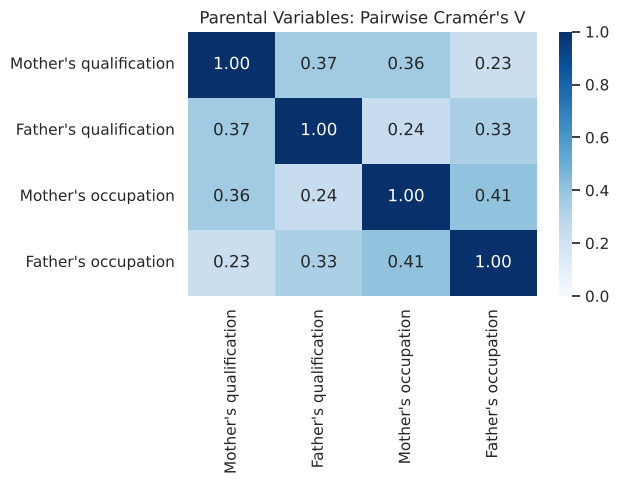

In [6]:
parental = ["Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
v_mat = pd.DataFrame(index=parental, columns=parental, dtype=float)
for a in parental:
    for b in parental:
        v_mat.loc[a, b] = 1.0 if a == b else cramers_v(pd.crosstab(df_collapsed[a], df_collapsed[b]))

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(v_mat, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("Parental Variables: Pairwise Cramér's V")
plt.tight_layout()
plt.show()

**Reading this:** with the correct measure, the associations are moderate, not extreme. Mother/father **occupation** (V ≈ 0.41) and mother/father **qualification** (V ≈ 0.37) are the strongest pairs, and each parent's own qualification and occupation are close behind (≈ 0.33-0.36). The cross pairs (one parent's qualification vs. the other parent's occupation) are weakest (≈ 0.23-0.24). Section 2 checks whether this is strong enough to cause a multicollinearity problem in the model.

## 2. Multicollinearity (supports 01, 02, 03)

### 2.1 Generalized VIF

A standard VIF gives one number per column, which doesn't work for a categorical predictor split into many dummies. The **generalized VIF** (Fox & Monette, 1992) gives one number per original variable. GVIF^(1/(2·df)) is on the same scale as √VIF, so the usual cutoffs apply after squaring: GVIF^(1/(2·df)) > √5 ≈ 2.24 is moderate, and > √10 ≈ 3.16 is serious.

In [7]:
def inference_design(data, cols, drop=()):
    """Design matrix for statsmodels: standardized numeric columns,
    drop-first dummies of the collapsed categoricals, binaries as-is."""
    cols = [c for c in cols if c not in drop]
    num = [c for c in NUMERIC_COLS if c in cols]
    cat = [c for c in CATEGORICAL_COLS if c in cols]
    binr = [c for c in BINARY_COLS if c in cols]
    Xn = (data[num] - data[num].mean()) / data[num].std()
    Xc = pd.get_dummies(df_collapsed.loc[data.index, cat], drop_first=True, dtype=float)
    return pd.concat([Xn, Xc, data[binr].astype(float)], axis=1)

def gvif_table(X):
    """GVIF for each original variable (groups dummy columns back together)."""
    R = np.corrcoef(X.values, rowvar=False)
    logdet_R = np.linalg.slogdet(R)[1]
    groups = {}
    for i, col in enumerate(X.columns):
        base = next((v for v in CATEGORICAL_COLS if col.startswith(v + "_")), col)
        groups.setdefault(base, []).append(i)
    rows = []
    for var, idx in groups.items():
        rest = [j for j in range(X.shape[1]) if j not in idx]
        log_gvif = (np.linalg.slogdet(R[np.ix_(idx, idx)])[1]
                    + np.linalg.slogdet(R[np.ix_(rest, rest)])[1] - logdet_R)
        gvif = np.exp(log_gvif)
        rows.append({"Variable": var, "df": len(idx), "GVIF": gvif,
                     "GVIF^(1/2df)": gvif ** (1 / (2 * len(idx)))})
    return pd.DataFrame(rows).sort_values("GVIF^(1/2df)", ascending=False).reset_index(drop=True)

gvif_all = gvif_table(inference_design(df, feature_sets["Full Data"]))
display(gvif_all.head(8).round(2))

,Variable,df,GVIF,GVIF^(1/2df)
0,International,1,1.801440e+15,42443372.29
1,Nacionality,1,1.801440e+15,42443372.29
2,Daytime/evening attendance,1,1.041295e+14,10204384.90
3,Curricular units 1st sem (enrolled),1,2.616000e+01,5.11
4,Curricular units 2nd sem (enrolled),1,2.021000e+01,4.50
5,Curricular units 2nd sem (credited),1,1.390000e+01,3.73
6,Curricular units 1st sem (approved),1,1.050000e+01,3.24
7,Curricular units 1st sem (credited),1,1.019000e+01,3.19


Three variables come out with absurd values (GVIF in the trillions). That isn't "high" collinearity. It means one column is an **exact** function of others, so the correlation matrix is singular. Section 2.2 identifies them.

### 2.2 Exact redundancies in the dataset

In [8]:
print("International vs. Nacionality == Portuguese (code 1):")
display(pd.crosstab(df["Nacionality"] == 1, df["International"]))

print("Daytime/evening attendance by Course (only courses with any evening students shown):")
ct = pd.crosstab(df["Course"], df["Daytime/evening attendance"])
display(ct[ct[0] > 0])

International vs. Nacionality == Portuguese (code 1):


International,0,1
Nacionality,,
False,0,110
True,4314,0


Daytime/evening attendance by Course (only courses with any evening students shown):


Daytime/evening attendance,0,1
Course,,
8014,215,0
9991,268,0


**Two exact redundancies:**

1. **International ≡ (Nacionality ≠ Portuguese).** All 110 non-Portuguese students are flagged International, and no Portuguese student is. The binary is fully contained in Nacionality.
2. **Daytime/evening attendance ≡ Course ∈ {8014, 9991}.** Those two courses are the evening versions of Social Service and Management. Every one of their students attends in the evening, and every student in every other course attends during the day.

This doesn't break the predictive models in 02-05. scikit-learn's default L2 penalty keeps the fit stable, and the predictions are the same either way. It does mean the coefficients for those columns **can't be interpreted on their own**, because the model can shift weight freely between, say, *International* and the *Nacionality* dummies. If we present coefficient plots, these two binaries should be dropped (or flagged). They are dropped from every model below.

In [9]:
ALIASED = ["International", "Daytime/evening attendance"]

gvif_full = gvif_table(inference_design(df, feature_sets["Full Data"], drop=ALIASED))
gvif_full["Flag"] = pd.cut(gvif_full["GVIF^(1/2df)"], [0, np.sqrt(5), np.sqrt(10), np.inf],
                           labels=["OK", "Moderate", "Serious"])
display(gvif_full.round(2))

,Variable,df,GVIF,GVIF^(1/2df),Flag
0,Curricular units 1st sem (enrolled),1,26.16,5.11,Serious
1,Curricular units 2nd sem (enrolled),1,20.45,4.52,Serious
2,Curricular units 1st sem (credited),1,17.50,4.18,Serious
3,Curricular units 2nd sem (credited),1,13.94,3.73,Serious
4,Curricular units 1st sem (approved),1,13.52,3.68,Serious
5,Curricular units 2nd sem (approved),1,11.39,3.38,Serious
6,Curricular units 2nd sem (grade),1,6.09,2.47,Moderate
7,Curricular units 1st sem (grade),1,5.40,2.32,Moderate
8,Curricular units 1st sem (evaluations),1,4.16,2.04,OK
9,Curricular units 2nd sem (evaluations),1,3.54,1.88,OK


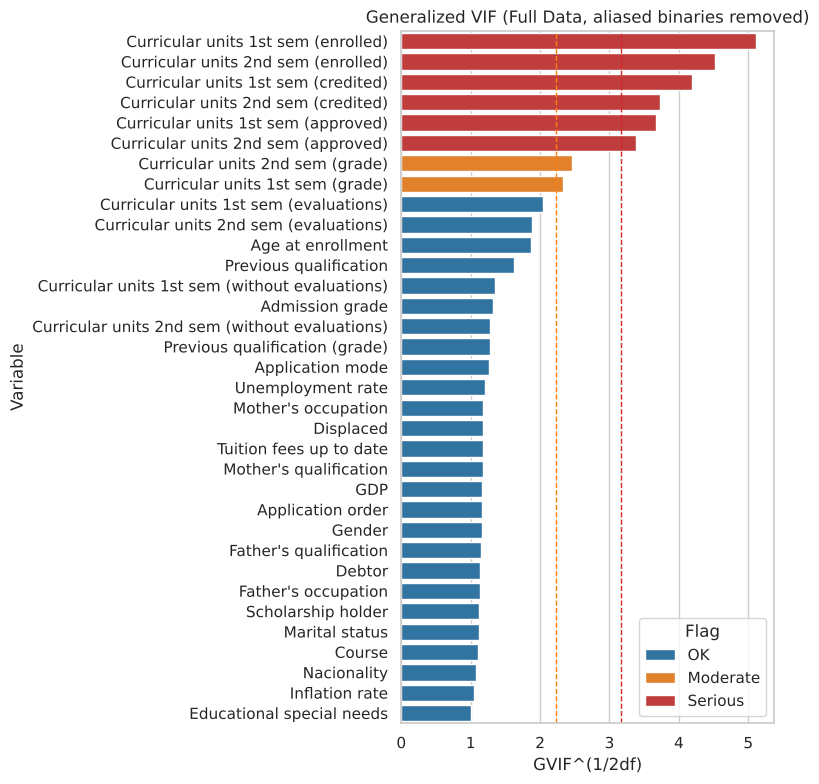

In [10]:
fig, ax = plt.subplots(figsize=(8, 8))
sns.barplot(data=gvif_full, y="Variable", x="GVIF^(1/2df)", hue="Flag", dodge=False,
            palette={"OK": "tab:blue", "Moderate": "tab:orange", "Serious": "tab:red"}, ax=ax)
ax.axvline(np.sqrt(5), ls="--", c="tab:orange", lw=1)
ax.axvline(np.sqrt(10), ls="--", c="tab:red", lw=1)
ax.set_title("Generalized VIF (Full Data, aliased binaries removed)")
plt.tight_layout()
fig.savefig(FIG_DIR / "gvif_full_data.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading this:**

- **The real multicollinearity is in the semester variables, not the parental ones.** *Enrolled*, *credited*, and *approved* (both semesters) are serious, and the two semester *grades* are moderate. That makes sense: approved ≤ enrolled, and the 1st and 2nd semester counts track each other closely. This is the same issue Alex's collinearity notebook works on.
- **The parental variables are fine** (GVIF^(1/2df) ≈ 1.1-1.2). Section 1.3 showed they are associated with *each other*, but jointly they add very little variance inflation to the model. This is consistent with the earlier decision to drop the grouping and SES feature engineering: collinearity among the parental variables is not hurting the model.
- *Course* is now in the normal range, since its redundancy with *Daytime/evening attendance* was removed.

## 3. Logistic regression assumptions (supports 02, 03)

scikit-learn's `LogisticRegression` is penalized and doesn't produce standard errors, so the formal tests use **statsmodels `MNLogit`** (unpenalized, unweighted multinomial logit, Graduate as the reference class) on the inference design from Section 2. The `class_weight="balanced"` model from 02 is still the one used for prediction. These fits are for testing assumptions and hypotheses only.

### 3.1 Likelihood-ratio test: does each stage of information add significant explanatory power?

Notebook 03 showed accuracy and macro F1 improving from Day 1 → After Semester 1 → Full Data. That comparison is on a single test split with no p-value. The models are **nested** (each feature set contains the previous one), so a likelihood-ratio test can formally test whether the added semester variables improve fit:

LR = 2 (ℓ_larger − ℓ_smaller) ~ χ²(Δ parameters)

In [11]:
y_code = y.map({"Graduate": 0, "Dropout": 1, "Enrolled": 2})   # Graduate = reference

mnlogit_fits = {}
for name in ["Day 1", "After Semester 1", "Full Data"]:
    X = sm.add_constant(inference_design(df, feature_sets[name], drop=ALIASED))
    fit = sm.MNLogit(y_code, X).fit(method="newton", maxiter=300, disp=0)
    mnlogit_fits[name] = fit
    print(f"{name:<17} params={fit.params.size:>4}  logLik={fit.llf:9.1f}  "
          f"McFadden R²={fit.prsquared:.3f}  converged={fit.mle_retvals['converged']}")

lrt_rows = []
for small, large in [("Day 1", "After Semester 1"), ("After Semester 1", "Full Data"), ("Day 1", "Full Data")]:
    lr = 2 * (mnlogit_fits[large].llf - mnlogit_fits[small].llf)
    ddf = mnlogit_fits[large].df_model - mnlogit_fits[small].df_model
    lrt_rows.append({"Comparison": f"{small} → {large}", "LR statistic": lr, "df": int(ddf),
                     "p-value": stats.chi2.sf(lr, ddf),
                     "Δ McFadden R²": mnlogit_fits[large].prsquared - mnlogit_fits[small].prsquared})
lrt_df = pd.DataFrame(lrt_rows)
display(lrt_df.round(4))

Day 1             params= 152  logLik=  -3417.7  McFadden R²=0.243  converged=True


After Semester 1  params= 164  logLik=  -2601.7  McFadden R²=0.423  converged=True


Full Data         params= 176  logLik=  -2317.2  McFadden R²=0.486  converged=True


,Comparison,LR statistic,df,p-value,Δ McFadden R²
0,Day 1 → After Semester 1,1631.9154,12,0.0,0.1808
1,After Semester 1 → Full Data,568.9923,12,0.0,0.0631
2,Day 1 → Full Data,2200.9077,24,0.0,0.2439


**Reading this:** both steps are overwhelmingly significant (p ≈ 0). The effect sizes tell the more useful story. Adding 1st-semester performance raises McFadden R² by about 0.18 (from ~0.24 to ~0.42). Adding the 2nd semester adds a smaller but still substantial ~0.06. This is the formal version of the feature-availability finding: **1st-semester data is the single biggest jump in information**, which supports flagging at-risk students right after the 1st semester.

(McFadden R² of 0.2-0.4 is generally considered a very good fit for a logit model. It isn't on the same scale as OLS R².)

### 3.2 Box-Tidwell: are the continuous predictors linear in the logit?

Logistic regression assumes each continuous predictor has a **linear** effect on the log-odds. The Box-Tidwell test adds an x·ln(x) term for each continuous predictor. If that term is significant, the relationship is nonlinear. It needs strictly positive x, so it's run on the three positive Day-1 continuous variables. (*Application order* includes 0, and the semester counts have structural zeros.)

In [12]:
bt_vars = ["Age at enrollment", "Admission grade", "Previous qualification (grade)"]
X_day1 = inference_design(df, feature_sets["Day 1"], drop=ALIASED)

X_bt = X_day1.copy()
for v in bt_vars:
    xlnx = df[v].astype(float) * np.log(df[v].astype(float))
    X_bt[f"{v} × ln"] = (xlnx - xlnx.mean()) / xlnx.std()

fit_bt = sm.MNLogit(y_code, sm.add_constant(X_bt)).fit(method="newton", maxiter=300, disp=0)

bt_rows = []
for v in bt_vars:
    fit_drop = sm.MNLogit(y_code, sm.add_constant(X_bt.drop(columns=[f"{v} × ln"]))).fit(
        method="newton", maxiter=300, disp=0)
    lr = 2 * (fit_bt.llf - fit_drop.llf)
    bt_rows.append({"Predictor": v, "LR statistic": lr, "df": 2, "p-value": stats.chi2.sf(lr, 2)})
bt_df = pd.DataFrame(bt_rows)
bt_df["Linear in logit?"] = np.where(bt_df["p-value"] < ALPHA, "No", "Yes")
display(bt_df.round(4))

,Predictor,LR statistic,df,p-value,Linear in logit?
0,Age at enrollment,22.9468,2,0.0000,No
1,Admission grade,0.9969,2,0.6075,Yes
2,Previous qualification (grade),5.0117,2,0.0816,Yes


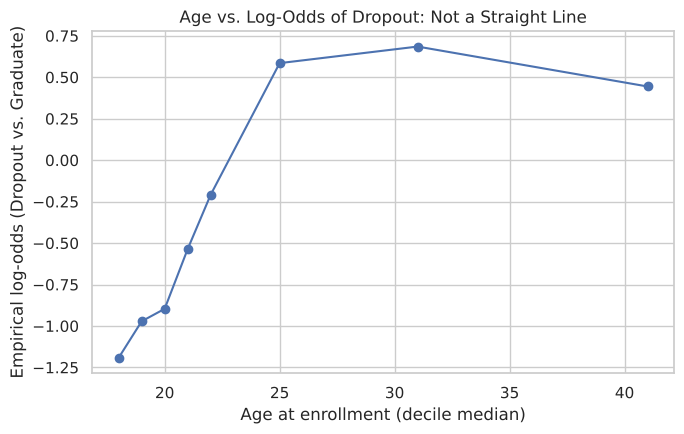

In [13]:
# Visual check: empirical log-odds of Dropout vs. Graduate across age deciles
age_bins = pd.qcut(df["Age at enrollment"], q=10, duplicates="drop")
sub = df[y.isin(["Dropout", "Graduate"])]
emp = (sub.groupby(age_bins.loc[sub.index], observed=True)[TARGET_COL]
          .apply(lambda s: np.log((s == "Dropout").mean() / (s == "Graduate").mean())))
mid = df.groupby(age_bins, observed=True)["Age at enrollment"].median()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(mid.values, emp.values, "o-")
ax.set_xlabel("Age at enrollment (decile median)")
ax.set_ylabel("Empirical log-odds (Dropout vs. Graduate)")
ax.set_title("Age vs. Log-Odds of Dropout: Not a Straight Line")
plt.tight_layout()
plt.show()

**Reading this:** *Admission grade* and *Previous qualification grade* pass (their effect on the log-odds is close enough to linear). **Age at enrollment fails:** dropout log-odds climb steeply from 18 to the mid-20s and then flatten out for older students. A single linear age coefficient understates the risk jump for students in their early-to-mid 20s and overstates it for the oldest students.

**Possible fixes for later rounds:** a spline or age bands (e.g. ≤19, 20-24, 25-34, 35+) in the logistic model. Tree models (RF, XGBoost) handle this automatically, which is one reason they can edge out LogReg.

### 3.3 Influential observations: Cook's distance

Cook's distance isn't standard for a multinomial model, so this uses the one-vs-rest **Dropout vs. not-Dropout** logit, which is the outcome we care most about. The common cutoffs are D > 1 (clearly influential) and D > 4/n (a lenient screening threshold).

Max Cook's D:      0.0136
Points with D > 1: 0
Points with D > 4/n (0.00090): 401 (9.1%)


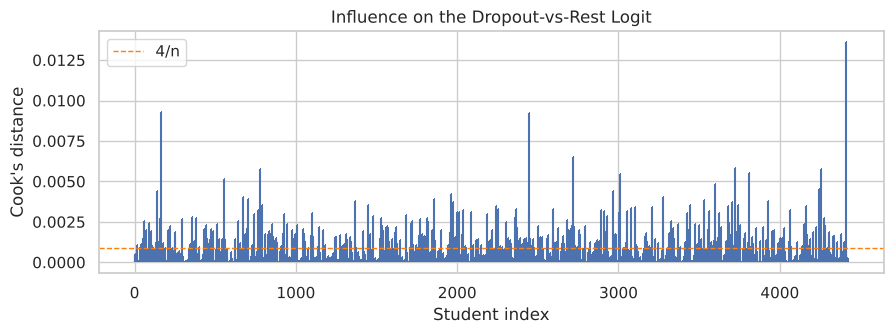

In [14]:
X_full = sm.add_constant(inference_design(df, feature_sets["Full Data"], drop=ALIASED))
y_dropout = (y == "Dropout").astype(int)
glm_dropout = sm.GLM(y_dropout, X_full, family=sm.families.Binomial()).fit()
cooks_d = glm_dropout.get_influence().cooks_distance[0]

print(f"Max Cook's D:      {cooks_d.max():.4f}")
print(f"Points with D > 1: {(cooks_d > 1).sum()}")
print(f"Points with D > 4/n ({4/len(df):.5f}): {(cooks_d > 4/len(df)).sum()} ({(cooks_d > 4/len(df)).mean():.1%})")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.stem(np.arange(len(cooks_d)), cooks_d, markerfmt=",", basefmt=" ")
ax.axhline(4 / len(df), ls="--", c="tab:orange", lw=1, label="4/n")
ax.set_xlabel("Student index")
ax.set_ylabel("Cook's distance")
ax.set_title("Influence on the Dropout-vs-Rest Logit")
ax.legend()
plt.tight_layout()
plt.show()

**Reading this:** no student comes close to D = 1 (the maximum is about 0.014), so **no single observation is driving the fit**, and no rows need to be removed. About 9% exceed the lenient 4/n line, but with n = 4,424 that threshold is tiny (≈ 0.0009) and flags a lot of ordinary students. Most of the flagged students are the "surprising" cases the model gets wrong, such as an Enrolled or Graduate student who looks like a dropout on paper.

## 4. Linear regression assumptions (supports notebook 06)

Refits the two main GPA regressions from notebook 06 with **statsmodels OLS** (same students, same feature sets, same structural-zero exclusion) and tests the classic assumptions:

| Assumption | Test | H₀ |
|---|---|---|
| Constant error variance | **Breusch-Pagan**; **White** (special-case form, using fitted values and fitted²) | Homoskedastic errors |
| Normal errors | **Jarque-Bera** (+ Q-Q plot) | Residual skew = 0 and kurtosis = 3 |
| Correct functional form | **Ramsey RESET** (adds ŷ²) | Linear specification is adequate |

The full White test (all squares and cross-products) would need ~2,800 auxiliary regressors with ~75 predictors, so the fitted-values version is used.

Independence of errors isn't tested. There is no time or spatial ordering of students, so Durbin-Watson doesn't apply.

In [15]:
sem1_col = "Curricular units 1st sem (grade)"
sem2_col = "Curricular units 2nd sem (grade)"
df_engaged_sem1 = df[df[sem1_col] > 0]
df_engaged_both = df[(df[sem1_col] > 0) & (df[sem2_col] > 0)]

ols_specs = {
    "Sem1 grade ~ Day 1": (df_engaged_sem1, feature_sets["Day 1"], sem1_col),
    "Sem2 grade ~ After Sem 1": (df_engaged_both, [c for c in feature_sets["After Semester 1"] if c != sem2_col], sem2_col),
}

ols_fits, diag_rows = {}, []
for name, (data, cols, target) in ols_specs.items():
    X = inference_design(data, cols, drop=ALIASED)
    X = sm.add_constant(X.loc[:, X.std() > 0])          # drop dummies that are constant in this subset
    fit = sm.OLS(data[target], X).fit()
    ols_fits[name] = fit

    bp_stat, bp_p, _, _ = het_breuschpagan(fit.resid, fit.model.exog)
    w_stat, w_p, _, _ = het_white(fit.resid, sm.add_constant(fit.fittedvalues.values))
    jb_stat, jb_p, skew, kurt = jarque_bera(fit.resid)
    reset = linear_reset(fit, power=2, use_f=True)

    diag_rows.append({
        "Model": name, "n": int(fit.nobs), "R²": fit.rsquared,
        "BP stat": bp_stat, "BP p": bp_p,
        "White stat": w_stat, "White p": w_p,
        "JB stat": jb_stat, "JB p": jb_p, "Skew": skew, "Kurtosis": kurt,
        "RESET F": reset.fvalue, "RESET p": reset.pvalue,
    })

ols_diag = pd.DataFrame(diag_rows).set_index("Model")
display(ols_diag.T.round(4))

Model,Sem1 grade ~ Day 1,Sem2 grade ~ After Sem 1
n,3706.0000,3512.0000
R²,0.2957,0.5328
BP stat,303.1791,335.8482
BP p,0.0000,0.0000
White stat,5.5642,39.9816
White p,0.0619,0.0000
JB stat,201.3640,172.5112
JB p,0.0000,0.0000
Skew,0.4423,0.3097
Kurtosis,3.7221,3.8917


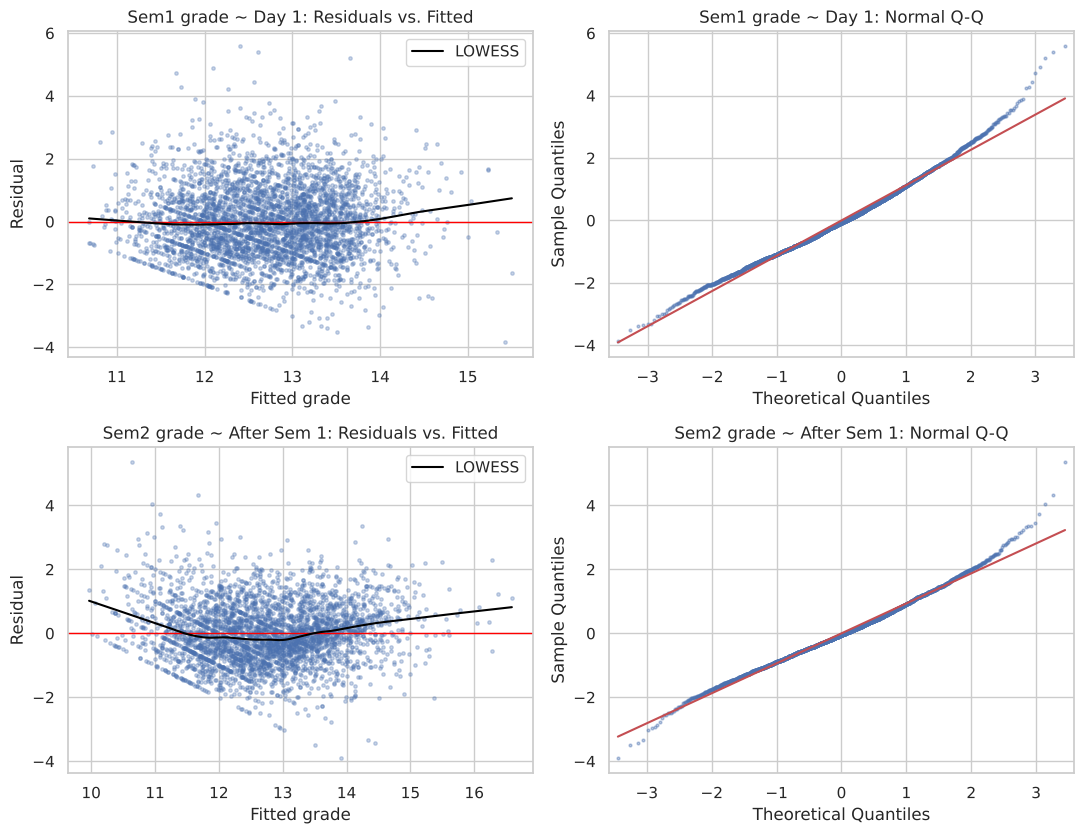

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
for row, (name, fit) in enumerate(ols_fits.items()):
    ax = axes[row, 0]
    ax.scatter(fit.fittedvalues, fit.resid, s=6, alpha=0.3)
    ax.axhline(0, c="red", lw=1)
    lowess = sm.nonparametric.lowess(fit.resid, fit.fittedvalues, frac=0.3)
    ax.plot(lowess[:, 0], lowess[:, 1], c="black", lw=1.5, label="LOWESS")
    ax.set_title(f"{name}: Residuals vs. Fitted")
    ax.set_xlabel("Fitted grade")
    ax.set_ylabel("Residual")
    ax.legend()

    sm.qqplot(fit.resid, line="s", ax=axes[row, 1], markersize=2, alpha=0.4)
    axes[row, 1].set_title(f"{name}: Normal Q-Q")
plt.tight_layout()
fig.savefig(FIG_DIR / "gpa_regression_residual_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading this:**

- **Heteroskedasticity (both models): rejected.** Breusch-Pagan strongly rejects for both. BP regresses the squared residuals on *all* predictors, so it picks up variance that differs by group (some courses have much more spread in grades than others) even when the spread doesn't change much with the fitted value. That's why the fitted-values White test is only borderline for Sem1 (p ≈ 0.06) but rejects for Sem2. Either way, classic OLS standard errors aren't reliable here, so 4.1 checks HC3 robust standard errors.
- The diagonal stripes in the residual plots aren't a problem. They come from grades being recorded on a coarse scale.
- **Normality: rejected, but it doesn't matter much here.** Jarque-Bera rejects, but the departure is mild (skew ≈ 0.3-0.4, kurtosis ≈ 3.7-3.9 vs. 3 for a normal). The Q-Q plots are close to the line except at the tails. With n > 3,500, the CLT makes coefficient inference robust to this.
- **Functional form:** RESET is fine for the Sem1 model (p ≈ 0.2) but **strongly rejects for the Sem2 model**. You can see it in the U-shaped LOWESS line: the model under-predicts at both ends of the grade range. The Sem2 relationship has curvature that a linear model misses, which is the regression version of the Box-Tidwell result in 3.2. A tree model or a few interaction or squared terms would probably raise the 0.43-0.53 R².

### 4.1 Does heteroskedasticity change any conclusions? Classic vs. HC3 robust standard errors

In [17]:
rob_rows = []
for name, fit in ols_fits.items():
    robust = fit.get_robustcov_results(cov_type="HC3")
    p_classic = fit.pvalues.drop("const")
    p_robust = pd.Series(robust.pvalues, index=fit.params.index).drop("const")
    flips = p_classic.index[(p_classic < ALPHA) != (p_robust < ALPHA)]
    rob_rows.append({"Model": name,
                     "Significant (classic SE)": int((p_classic < ALPHA).sum()),
                     "Significant (HC3 SE)": int((p_robust < ALPHA).sum()),
                     "Terms that flip": ", ".join(flips) if len(flips) else "none"})
display(pd.DataFrame(rob_rows))

,Model,Significant (classic SE),Significant (HC3 SE),Terms that flip
0,Sem1 grade ~ Day 1,24,23,Course_9130
1,Sem2 grade ~ After Sem 1,18,18,"Course_9500, Tuition fees up to date"


**Reading this:** switching to HC3 robust standard errors flips the significance of only one or two individual course/tuition dummies per model, and none of the headline variables. So the heteroskedasticity is real, but **none of notebook 06's conclusions depend on it.** If we report coefficient p-values from these regressions, we should still report the HC3 versions.

## 5. Is the Random Forest really better than Logistic Regression? (supports notebook 07)

Notebook 07 shows RF slightly ahead of LogReg. Two tests check whether that gap is bigger than chance:

1. **McNemar's test** on the shared 80/20 test set. It only uses the students where the two models *disagree* about correctness. H₀: both models have the same error rate.
2. **Corrected resampled t-test** (Nadeau & Bengio, 2003) on 5-fold × 3-repeat CV scores. A plain paired t-test on CV folds is **too optimistic**, because the training sets overlap across folds, so the fold scores aren't independent. The correction inflates the variance by (1/k + n_test/n_train).

In [18]:
full_cols = feature_sets["Full Data"]
_, _, _, y_test, pred_lr = evaluate_feature_set(df, full_cols, "Full Data", get_logistic_regression(),
                                                scale_numeric=True, return_split=True)
_, _, _, y_test_rf, pred_rf = evaluate_feature_set(df, full_cols, "Full Data", get_random_forest(),
                                                   scale_numeric=False, return_split=True)
assert (y_test.values == y_test_rf.values).all()   # same split, so the pairing is valid

lr_correct = pd.Series(pred_lr == y_test.values, name="LogReg correct")
rf_correct = pd.Series(pred_rf == y_test.values, name="RF correct")
mc_table = pd.crosstab(lr_correct, rf_correct)
display(mc_table)

mc = mcnemar(mc_table.values, exact=False, correction=True)
print(f"LogReg accuracy: {lr_correct.mean():.3f} | RF accuracy: {rf_correct.mean():.3f}")
print(f"McNemar χ² = {mc.statistic:.2f}, p = {mc.pvalue:.4f}")

RF correct,False,True
LogReg correct,,
False,164,78
True,46,597


LogReg accuracy: 0.727 | RF accuracy: 0.763
McNemar χ² = 7.75, p = 0.0054


In [19]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
X_cv, y_cv = df[full_cols], y
scoring = {"accuracy": "accuracy", "macro_f1": "f1_macro"}

cv_lr = cross_validate(build_model_pipeline(get_logistic_regression(), full_cols, scale_numeric=True),
                       X_cv, y_cv, cv=cv, scoring=scoring, n_jobs=-1)
cv_rf = cross_validate(build_model_pipeline(get_random_forest(), full_cols, scale_numeric=False),
                       X_cv, y_cv, cv=cv, scoring=scoring, n_jobs=-1)

def corrected_resampled_ttest(a, b, test_frac=0.2):
    d = a - b
    k = len(d)
    t = d.mean() / np.sqrt((1 / k + test_frac / (1 - test_frac)) * d.var(ddof=1))
    return t, 2 * stats.t.sf(abs(t), k - 1)

rows = []
for m in scoring:
    a, b = cv_lr[f"test_{m}"], cv_rf[f"test_{m}"]
    t_c, p_c = corrected_resampled_ttest(a, b)
    t_n, p_n = stats.ttest_rel(a, b)
    rows.append({"Metric": m, "LogReg mean": a.mean(), "RF mean": b.mean(), "Diff (LR − RF)": a.mean() - b.mean(),
                 "Naive paired t p": p_n, "Corrected t p": p_c})
cv_tests = pd.DataFrame(rows)
display(cv_tests.round(4))

,Metric,LogReg mean,RF mean,Diff (LR − RF),Naive paired t p,Corrected t p
0,accuracy,0.7489,0.7747,-0.0258,0.0000,0.0016
1,macro_f1,0.7084,0.7192,-0.0108,0.0093,0.1885


**Reading this:** the tests disagree in an informative way.

- On the single test split, **McNemar says RF's accuracy edge is significant**. RF gets right more of the students LogReg misses than the reverse.
- Across 15 CV fits, the **naive** paired t-test also says "significant", but once the fold-overlap correction is applied, the macro-F1 difference is **not significant**. RF's accuracy advantage holds up better than its macro-F1 advantage. Accuracy is driven by the large Graduate class, while macro F1 weights the hard Enrolled class equally, and there the models are much closer.

**Takeaway for the presentation:** RF is slightly but consistently more accurate. On the balanced metric we care about (macro F1, which treats Enrolled fairly), we can't claim it's better than the interpretable LogReg. That's a good argument for keeping LogReg as the explanatory model.

## 6. Summary

In [20]:
top_v = chi_df["Cramér's V"].iloc[0]
summary = pd.DataFrame([
    ["1.1", "Categorical predictors associated with outcome", "Chi-square + Cramér's V",
     f"{int(chi_df['Significant'].sum())}/{len(chi_df)} significant; strongest: {chi_df.iloc[0]['Predictor']} (V={top_v:.2f})"],
    ["1.2", "Numeric predictors differ by outcome", "Kruskal-Wallis + ε²",
     f"{int(kw_df['Significant'].sum())}/{len(kw_df)} significant; strongest: {kw_df.iloc[0]['Predictor']} (ε²={kw_df.iloc[0]['ε²']:.2f})"],
    ["2.2", "No exact redundancies", "Crosstab / GVIF",
     "Violated: International ≡ Nacionality; Daytime/evening ≡ Course"],
    ["2.1", "No serious multicollinearity", "Generalized VIF",
     f"{(gvif_full['Flag'] != 'OK').sum()} variables flagged, all semester counts; parental vars OK"],
    ["3.1", "Semester data adds information", "Likelihood-ratio test",
     f"Yes: ΔR² Day1→Sem1 = {lrt_df.iloc[0]['Δ McFadden R²']:.2f}, Sem1→Full = {lrt_df.iloc[1]['Δ McFadden R²']:.2f}"],
    ["3.2", "Linearity in the logit", "Box-Tidwell",
     "Violated for: " + ", ".join(bt_df.loc[bt_df['Linear in logit?'] == 'No', 'Predictor']) if (bt_df['Linear in logit?'] == 'No').any() else "Holds"],
    ["3.3", "No overly influential points", "Cook's distance", f"Holds (max D = {cooks_d.max():.3f})"],
    ["4", "Homoskedastic OLS errors (06)", "Breusch-Pagan / White", "Violated, but HC3 flips only 1-2 minor terms"],
    ["4", "Normal OLS errors (06)", "Jarque-Bera + Q-Q", "Mildly violated; fine at this n"],
    ["4", "Linear functional form (06)", "Ramsey RESET",
     "; ".join(f"{m}: {'OK' if p >= ALPHA else 'violated'}" for m, p in ols_diag['RESET p'].items())],
    ["5", "RF beats LogReg", "McNemar / corrected t",
     f"Accuracy: yes (McNemar p={mc.pvalue:.3f}); macro F1: not significant (corrected p={cv_tests.loc[cv_tests.Metric=='macro_f1','Corrected t p'].iloc[0]:.2f})"],
], columns=["§", "Assumption / claim", "Test", "Result"])

pd.set_option("display.max_colwidth", None)
display(summary)

,§,Assumption / claim,Test,Result
0,1.1,Categorical predictors associated with outcome,Chi-square + Cramér's V,14/17 significant; strongest: Tuition fees up to date (V=0.43)
1,1.2,Numeric predictors differ by outcome,Kruskal-Wallis + ε²,17/19 significant; strongest: Curricular units 2nd sem (approved) (ε²=0.43)
2,2.2,No exact redundancies,Crosstab / GVIF,Violated: International ≡ Nacionality; Daytime/evening ≡ Course
3,2.1,No serious multicollinearity,Generalized VIF,"8 variables flagged, all semester counts; parental vars OK"
4,3.1,Semester data adds information,Likelihood-ratio test,"Yes: ΔR² Day1→Sem1 = 0.18, Sem1→Full = 0.06"
5,3.2,Linearity in the logit,Box-Tidwell,Violated for: Age at enrollment
6,3.3,No overly influential points,Cook's distance,Holds (max D = 0.014)
7,4,Homoskedastic OLS errors (06),Breusch-Pagan / White,"Violated, but HC3 flips only 1-2 minor terms"
8,4,Normal OLS errors (06),Jarque-Bera + Q-Q,Mildly violated; fine at this n
9,4,Linear functional form (06),Ramsey RESET,Sem1 grade ~ Day 1: OK; Sem2 grade ~ After Sem 1: violated


### What to act on

1. **Drop `International` and `Daytime/evening attendance`** from any model whose *coefficients* we interpret (they are exact duplicates of Nacionality and Course). The predictions don't change.
2. **Model age nonlinearly** (bands or a spline) in the logistic regression.
3. **Address the semester-count collinearity** (enrolled / approved / credited across both semesters). This is the multicollinearity that actually matters, and it's what Alex's collinearity notebook tackles. The parental variables don't need special treatment.
4. **Report HC3 standard errors** for any coefficient-level claims from notebook 06, and consider a nonlinear term for the Sem2 regression.
5. **Frame RF vs. LogReg carefully:** RF has a small, significant accuracy edge, but no significant macro-F1 edge.